# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 2: Electrical Grid Stability Classification
### Dataset: Electrical Grid Stability Simulated Data (UCI Machine Learning Repository)

| **Field** | **Details** |
|---|---|
| **Student** | Hoang Huu Hoan |
| **Student ID** | 105732188 |
| **Task** | Portfolio Assessment 2 (Advanced Data Preprocessing, Feature Engineering & Model Development) |
| **Submission Date** | 12 October 2026 |


## Acknowledgement of Country

I acknowledge the Wurundjeri People of the Kulin Nation as Traditional Owners of the lands
where Swinburne's Australian campuses are located, and pay respect to Elders past and present.
I also acknowledge Traditional Owners across Australia. This adapts Swinburne's institutional
acknowledgement; it does not assume that this analysis was completed on an Australian campus.
Source: [Swinburne Moondani Toombadool Centre](https://www.swinburne.edu.au/about/strategy-initiatives/moondani-toombadool-centre/).

## Generative AI declaration

I use GenAI to assist with structuring the analysis code, suggesting data-quality checks, debugging, improving code readability, and comments and plot labelling. All final code, interpretations, and conclusions are my own work after verification.

## Reproducibility and setup

Run all cells from this folder using Python 3.13 and the versions printed below. All assessment
analysis code is in this notebook. The default performs the full searches; eight search workers
are capped by available CPUs. Supporting files contain export utilities, not hidden model logic.
The dataset hash, split indices, outer folds, parameters, search records, predictions and tables
are saved locally. Long searches print progress and can take several minutes.

In [1]:
from pathlib import Path
import os, sys, time, json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import pointbiserialr
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, ParameterGrid)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'data/Data_for_UCI_named.csv').exists(), 'Run from the notebook folder.'
for folder in ['figures', 'tables', 'results', 'evidence']:
    (ROOT / folder).mkdir(exist_ok=True)
SEED = 42
N_JOBS = min(8, os.cpu_count() or 1)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 110)
VERSIONS = {m: importlib.metadata.version(m) for m in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient']}
VERSIONS['python'] = platform.python_version()
(ROOT / 'results/environment.json').write_text(json.dumps(VERSIONS, indent=2))
print(json.dumps(VERSIONS, indent=2))
print('Search workers:', N_JOBS)

def table(frame, filename=None, digits=4):
    if filename:
        frame.to_csv(ROOT / 'tables' / (filename + '.csv'), index=False)
    display(frame.round(digits))

def savefig(name):
    plt.tight_layout()
    plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

def explain(text):
    display(Markdown(text))

def metrics(y_true, prediction):
    return {'accuracy': accuracy_score(y_true, prediction),
            'balanced_accuracy': balanced_accuracy_score(y_true, prediction),
            'macro_f1': f1_score(y_true, prediction, average='macro'),
            'stable_recall': recall_score(y_true, prediction, pos_label=0),
            'unstable_recall': recall_score(y_true, prediction, pos_label=1)}

{
  "numpy": "2.3.1",
  "pandas": "2.3.0",
  "scipy": "1.17.1",
  "scikit-learn": "1.8.0",
  "matplotlib": "3.10.8",
  "nbformat": "5.10.4",
  "nbclient": "0.10.4",
  "python": "3.13.9"
}
Search workers: 8


## Task 1: Target preparation and data audit

The applicable categorical-target branch is retained: stable = 0, unstable = 1. No numerical
binning is needed. Neither class exceeds the plan's 80% severe-imbalance threshold, so no
resampling is used. Accuracy is supplemented by balanced accuracy, macro-F1 and both recalls.

`stab` is excluded because its sign determines `stabf`. `p1` is excluded for continuity with Task 1
because it is the negative sum of consumer powers; this is redundancy, distinct from target leakage.
All remaining 11 inputs are continuous, so no categorical predictor encoding is required.

{
  "rows": 10000,
  "missing_cells": 0,
  "duplicate_rows": 0,
  "duplicate_configurations": 0,
  "label_sign_disagreements": 0,
  "maximum_power_balance_error": 5.773159728050814e-15,
  "source_sha256": "7afc3154fed9cd65258b3403b60381fe6b0d832bf817a1ea4866395d05a84a83"
}


,Class,Code,Count,Percent
0,stable,0,3620,36.2
1,unstable,1,6380,63.8


,Variables,Action,Reason / units
0,tau1-tau4,Keep,Reaction times; seconds
1,p2-p4,Keep,Consumer powers; inverse seconds squared
2,g1-g4,Keep,Elasticities; inverse seconds
3,p1,Exclude,Redundant: -(p2+p3+p4)
4,stab,Exclude,Target leakage: sign determines the label
5,stabf,Target only,"Map stable=0, unstable=1"


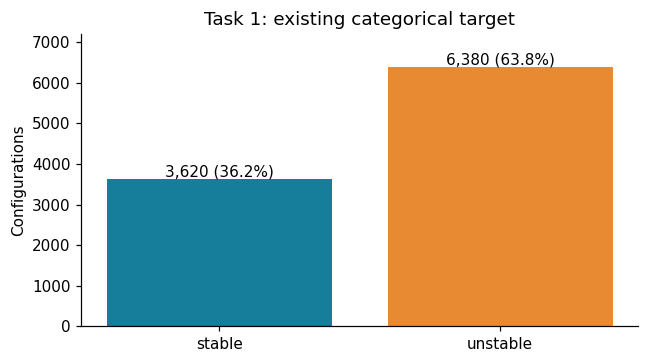

In [2]:
DATA = ROOT / 'data/Data_for_UCI_named.csv'
data_hash = hashlib.sha256(DATA.read_bytes()).hexdigest()
df = pd.read_csv(DATA)
ORIGINAL = ['tau1','tau2','tau3','tau4','p2','p3','p4','g1','g2','g3','g4']
TAU = ['tau1','tau2','tau3','tau4']
G = ['g1','g2','g3','g4']
DOMAIN = TAU + G
ENGINEERED = ['tau_mean','g_mean','tau_g_interaction','fast_node_fraction']
POOL = ORIGINAL + ENGINEERED
assert df.shape == (10000, 14)
assert set(df.stabf.unique()) == {'stable', 'unstable'}
y = df.stabf.map({'stable': 0, 'unstable': 1}).astype(int)
X = df.loc[:, ORIGINAL].copy()
audit = {'rows': len(df), 'missing_cells': int(df.isna().sum().sum()),
         'duplicate_rows': int(df.duplicated().sum()),
         'duplicate_configurations': int(df.duplicated(subset=ORIGINAL).sum()),
         'label_sign_disagreements': int(((df.stab > 0).astype(int) != y).sum()),
         'maximum_power_balance_error': float(abs(df.p1 + df.p2 + df.p3 + df.p4).max()),
         'source_sha256': data_hash}
for columns, low, high in [(TAU, .5, 10), (G, .05, 1), (['p2','p3','p4'], -2, -.5)]:
    assert df[columns].ge(low).all().all() and df[columns].le(high).all().all()
assert audit['missing_cells'] == audit['duplicate_rows'] == audit['duplicate_configurations'] == 0
assert audit['label_sign_disagreements'] == 0
assert audit['maximum_power_balance_error'] < 1e-10
(ROOT / 'results/data_audit.json').write_text(json.dumps(audit, indent=2))
print(json.dumps(audit, indent=2))
class_counts = df.stabf.value_counts().reindex(['stable','unstable'])
target_table = pd.DataFrame({'Class': class_counts.index, 'Code': [0,1],
                             'Count': class_counts.values, 'Percent': class_counts.values/100})
table(target_table, 'target_distribution')
inclusion = pd.DataFrame([
    ['tau1-tau4', 'Keep', 'Reaction times; seconds'],
    ['p2-p4', 'Keep', 'Consumer powers; inverse seconds squared'],
    ['g1-g4', 'Keep', 'Elasticities; inverse seconds'],
    ['p1', 'Exclude', 'Redundant: -(p2+p3+p4)'],
    ['stab', 'Exclude', 'Target leakage: sign determines the label'],
    ['stabf', 'Target only', 'Map stable=0, unstable=1']
], columns=['Variables','Action','Reason / units'])
table(inclusion, 'feature_inclusion')
fig, ax = plt.subplots(figsize=(6,3.4))
bars = ax.bar(target_table.Class, target_table.Count, color=['#167d9a','#e78a32'])
ax.bar_label(bars, labels=[f'{n:,} ({p:.1f}%)' for n,p in zip(target_table.Count,target_table.Percent)])
ax.set(ylim=(0,7200), ylabel='Configurations', title='Task 1: existing categorical target')
savefig('01_target_distribution')

## Evaluation protocol (locked before comparisons)

Use one stratified 70/30 split, seed 42: 7,000 development and 3,000 holdout rows. All models
share five shuffled stratified outer development folds. Tuned SVMs use five inner folds (seed 43)
on each outer training partition, then one full-development search for the final model.
The inner winning score is a selection score, not the outer evaluation score.

Rank by mean development CV accuracy. Define a near tie as at most 0.2 percentage points below
the best mean; prefer fewer resulting features/components, then fewer support vectors for SVMs,
then higher mean accuracy. This rule is applied before holdout prediction. Error bars are fold SD
(sample SD, ddof=1), not confidence intervals. CV balanced accuracy, macro-F1 and recalls are also saved.
Model-family selection can still be optimistic; the fixed holdout provides a separate final check
within the already-explored simulated dataset.

,Split,accuracy,balanced_accuracy,macro_f1,stable_recall,unstable_recall
0,development,0.638,0.5,0.3895,0.0,1.0
1,holdout,0.638,0.5,0.3895,0.0,1.0


,Split,Rows,Stable,Unstable
0,development,7000,2534,4466
1,holdout,3000,1086,1914


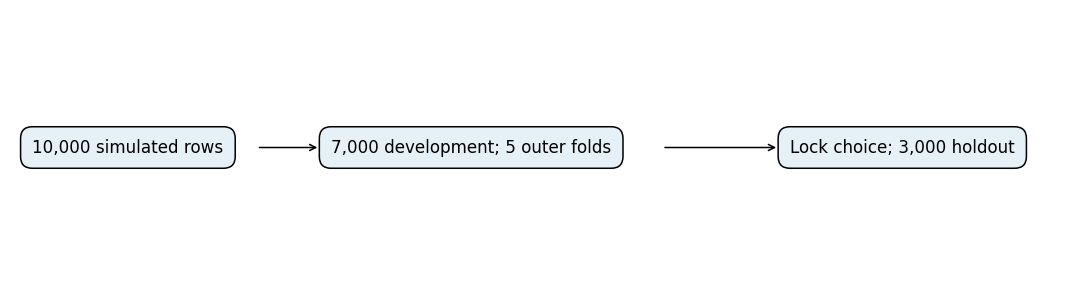

In [3]:
dev_idx, test_idx = train_test_split(np.arange(len(df)), test_size=.30,
                                   random_state=SEED, stratify=y)
X_dev, X_test = X.iloc[dev_idx].copy(), X.iloc[test_idx].copy()
y_dev, y_test = y.iloc[dev_idx].copy(), y.iloc[test_idx].copy()
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
OUTER_FOLDS = list(outer.split(X_dev, y_dev))
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED+1)
split_table = pd.DataFrame({'row_index': np.r_[dev_idx, test_idx],
                            'split': ['development']*len(dev_idx)+['holdout']*len(test_idx)})
split_table.to_csv(ROOT / 'results/split_indices.csv', index=False)
fold_id = np.full(len(X_dev), -1)
for fold, (a,b) in enumerate(OUTER_FOLDS):
    fold_id[b] = fold+1
pd.DataFrame({'row_index': dev_idx, 'outer_validation_fold': fold_id}).to_csv(
    ROOT / 'results/outer_folds.csv', index=False)
assert not set(dev_idx) & set(test_idx)
assert len(set(dev_idx) | set(test_idx)) == 10000
dummy = DummyClassifier(strategy='most_frequent').fit(X_dev, y_dev)
table(pd.DataFrame([{'Split':'development', **metrics(y_dev,dummy.predict(X_dev))},
                    {'Split':'holdout', **metrics(y_test,dummy.predict(X_test))}]), 'majority_reference')
table(pd.DataFrame([{'Split': name, 'Rows':len(labels),
                     'Stable':int((labels==0).sum()), 'Unstable':int((labels==1).sum())}
                    for name,labels in [('development',y_dev),('holdout',y_test)]]), 'split_counts')
fig, ax = plt.subplots(figsize=(10,2.8))
ax.axis('off')
for xpos,text in [(.02,'10,000 simulated rows'),(.30,'7,000 development; 5 outer folds'),
                 (.73,'Lock choice; 3,000 holdout')]:
    ax.text(xpos,.5,text,ha='left',va='center',bbox={'boxstyle':'round,pad=.7','fc':'#e5f1f6'},fontsize=11)
ax.annotate('',xy=(.29,.5),xytext=(.23,.5),arrowprops={'arrowstyle':'->'})
ax.annotate('',xy=(.72,.5),xytext=(.61,.5),arrowprops={'arrowstyle':'->'})
savefig('02_evaluation_protocol')

## Task 2: Normalisation and encoding

Task 1 Section 4 / Figure 4 and `distribution_check.csv` support MinMaxScaler for each original
uniform predictor. This changes range, not distribution shape. Trees generally keep the same
split ordering under monotonic scaling; scaling alone is not claimed to improve their accuracy.
SVM distances and PCA are scale-sensitive. No predictor needs one-hot or ordinal encoding.

The two node means use StandardScaler because aggregation makes their development distributions
more bell-shaped. The skewed product uses MinMaxScaler. The bounded fast-node fraction retains
its natural [0,1] scale. These choices are fixed before comparisons. The displays below fit a
separate descriptive scaler only on development data; model pipelines learn their own scalers
within every fold. A holdout value just outside [0,1] is possible and does not justify refitting.

,Feature,Action,Skew
0,tau1,MinMaxScaler,0.0023
1,tau2,MinMaxScaler,0.0113
2,tau3,MinMaxScaler,0.0038
3,tau4,MinMaxScaler,0.0063
4,p2,MinMaxScaler,0.0078
5,p3,MinMaxScaler,0.0055
6,p4,MinMaxScaler,0.0064
7,g1,MinMaxScaler,0.0069
8,g2,MinMaxScaler,-0.0101
9,g3,MinMaxScaler,-0.0155


,Feature,Before min,Before max,Before mean,Before SD
0,tau1,0.5008,9.9995,5.2469,2.7475
1,tau2,0.5001,9.9998,5.2319,2.7495
2,tau3,0.5008,9.9995,5.2578,2.7403
3,tau4,0.5005,9.9994,5.2426,2.7271
4,p2,-1.9997,-0.5001,-1.2500,0.4314
5,p3,-1.9997,-0.5001,-1.2561,0.4335
6,p4,-1.9999,-0.5000,-1.2507,0.4338
7,g1,0.0500,0.9999,0.5231,0.2743
8,g2,0.0501,0.9999,0.5263,0.2747
9,g3,0.0501,1.0000,0.5268,0.2728


,Feature,After min,After max,After mean,After SD
0,tau1,0.0000,1.0000,0.4997,0.2893
1,tau2,0.0000,1.0000,0.4981,0.2894
2,tau3,0.0000,1.0000,0.5008,0.2885
3,tau4,0.0000,1.0000,0.4992,0.2871
4,p2,0.0000,1.0000,0.5000,0.2877
5,p3,0.0000,1.0000,0.4959,0.2891
6,p4,0.0000,1.0000,0.4995,0.2892
7,g1,0.0000,1.0000,0.4980,0.2888
8,g2,0.0000,1.0000,0.5013,0.2893
9,g3,0.0000,1.0000,0.5018,0.2871


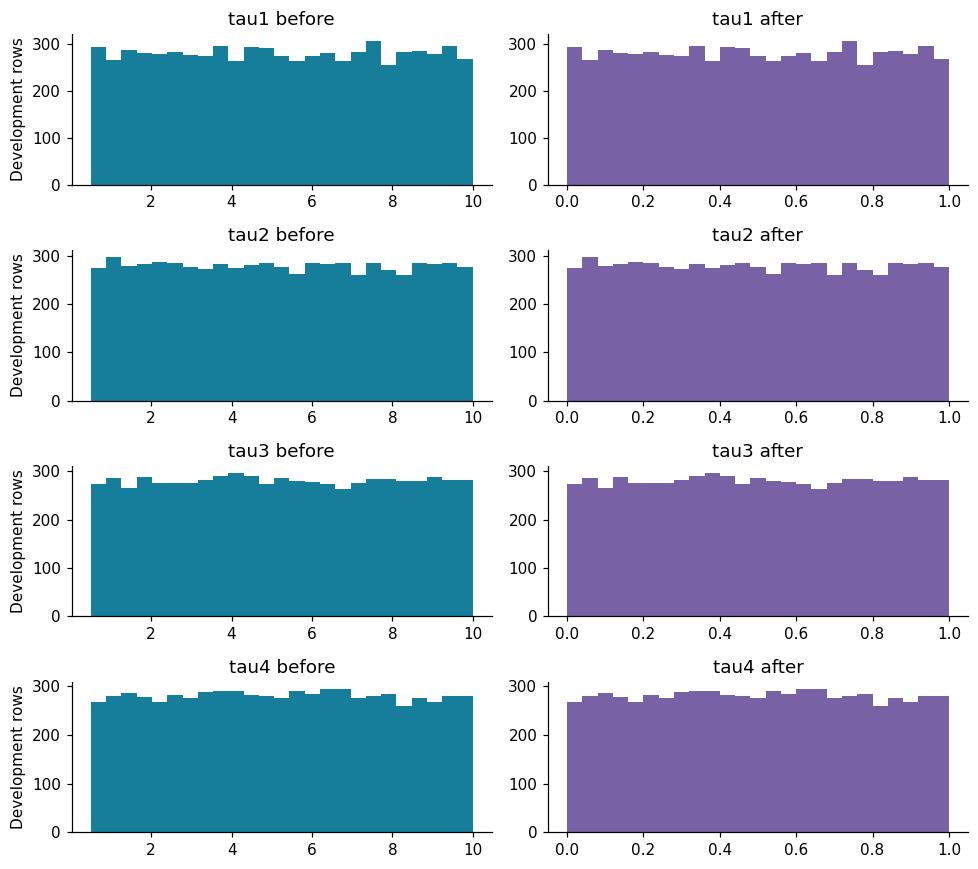

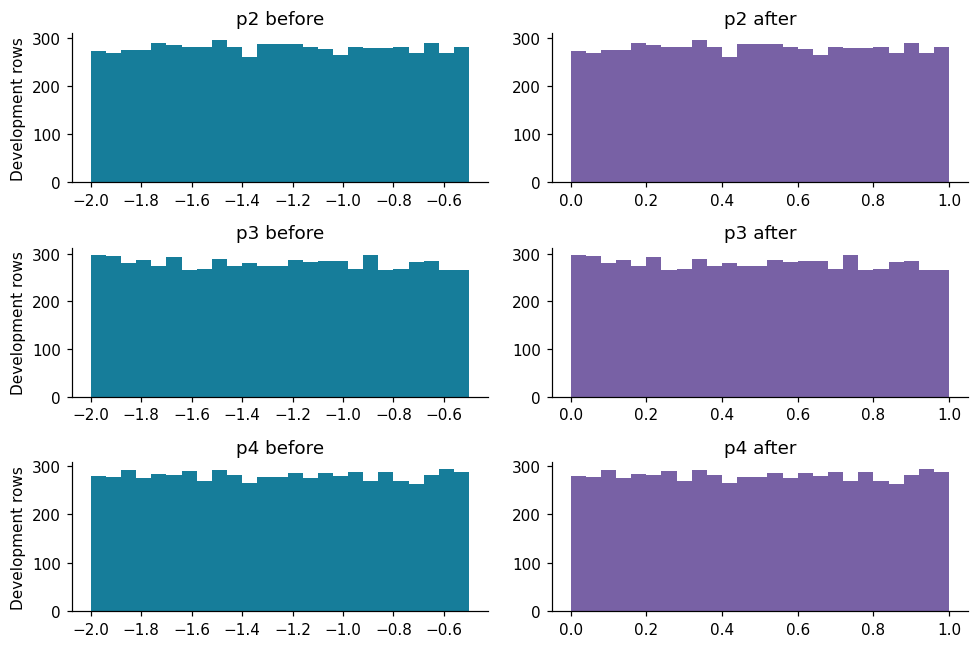

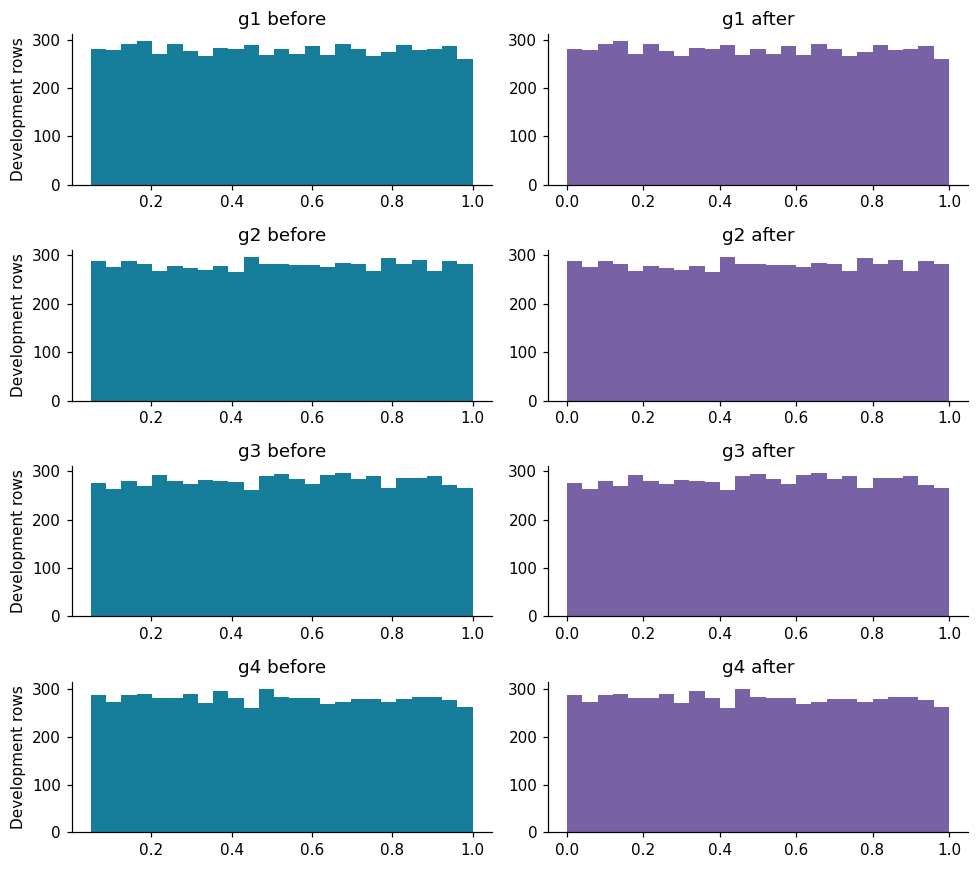

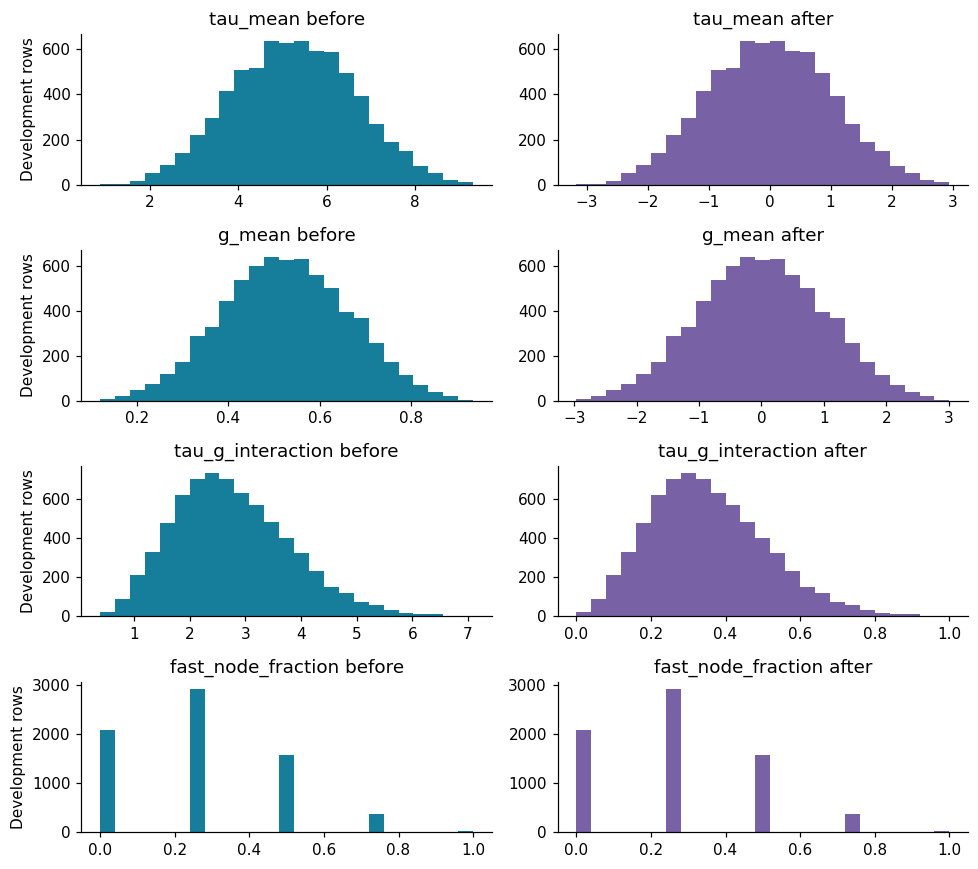

The retained original predictors have approximately symmetric, flat distributions. The feature-specific before/after tables use development rows only. StandardScaler uses population SD (ddof=0), so the displayed sample SD can differ slightly from 1. The fast-node fraction is discrete at 0, 0.25, 0.5, 0.75 and 1.

In [4]:
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def transform(self, X):
        out = X.loc[:, ORIGINAL].copy()
        out['tau_mean'] = out[TAU].mean(axis=1)
        out['g_mean'] = out[G].mean(axis=1)
        out['tau_g_interaction'] = out.tau_mean * out.g_mean
        out['fast_node_fraction'] = (out[TAU] <= 3.0).mean(axis=1)
        return out
    def get_feature_names_out(self, input_features=None):
        return np.asarray(POOL, dtype=object)

def mixed_scaler():
    return ColumnTransformer([
        ('minmax', MinMaxScaler(), ORIGINAL + ['tau_g_interaction']),
        ('standard', StandardScaler(), ['tau_mean','g_mean']),
        ('fraction', 'passthrough', ['fast_node_fraction'])
    ], verbose_feature_names_out=False).set_output(transform='pandas')

raw_dev = FeatureBuilder().fit_transform(X_dev)
descriptive_scaler = mixed_scaler().fit(raw_dev)
scaled_dev = descriptive_scaler.transform(raw_dev).loc[:, POOL]
preprocess_rows = []
for feature in POOL:
    method = ('StandardScaler' if feature in ['tau_mean','g_mean'] else
              'Natural [0,1]' if feature=='fast_node_fraction' else 'MinMaxScaler')
    r, s = raw_dev[feature], scaled_dev[feature]
    preprocess_rows.append({'Feature': feature, 'Action':method, 'Skew':r.skew(),
        'Before min':r.min(),'Before max':r.max(),'Before mean':r.mean(),'Before SD':r.std(),
        'After min':s.min(),'After max':s.max(),'After mean':s.mean(),'After SD':s.std()})
preprocessing = pd.DataFrame(preprocess_rows)
table(preprocessing[['Feature','Action','Skew']], 'preprocessing_decisions')
table(preprocessing[['Feature','Before min','Before max','Before mean','Before SD']], 'preprocessing_before')
table(preprocessing[['Feature','After min','After max','After mean','After SD']], 'preprocessing_after')
for group_id, group in enumerate([TAU, ['p2','p3','p4'], G, ENGINEERED], start=1):
    fig, axes = plt.subplots(len(group),2,figsize=(9,2.0*len(group)))
    for row, feature in enumerate(group):
        axes[row,0].hist(raw_dev[feature],bins=25,color='#167d9a')
        axes[row,1].hist(scaled_dev[feature],bins=25,color='#7861a5')
        axes[row,0].set_title(feature+' before'); axes[row,1].set_title(feature+' after')
        axes[row,0].set_ylabel('Development rows')
    savefig(f'03_scaling_group_{group_id}')
explain('The retained original predictors have approximately symmetric, flat distributions. '
        'The feature-specific before/after tables use development rows only. StandardScaler '
        'uses population SD (ddof=0), so the displayed sample SD can differ slightly from 1. '
        'The fast-node fraction is discrete at 0, 0.25, 0.5, 0.75 and 1.')

## Task 3: Four features grounded in existing EDA

| Feature | Formula and units | Exact Task 1 link and meaning |
|---|---|---|
| tau_mean | (tau1+tau2+tau3+tau4)/4; seconds | Section 5 Figure 8: aggregate reaction delay |
| g_mean | (g1+g2+g3+g4)/4; inverse seconds | Section 5 Figure 8: average price-response sensitivity |
| tau_g_interaction | tau_mean*g_mean; dimensionless | Section 5 Figure 8: joint delay/elasticity pattern |
| fast_node_fraction | count(tau_i <= 3 s)/4; dimensionless | Section 5 Figures 6-7: fast-response region |

The 3-second threshold is a fixed approximate EDA hypothesis, not a physical safety limit.
The product is a predictive composite, not a proven stability law. Each feature is validated below
using development-only associations, class distributions and binned unstable rates. These analyses
are descriptive; no p-value is used to select or redesign a feature after viewing the holdout.

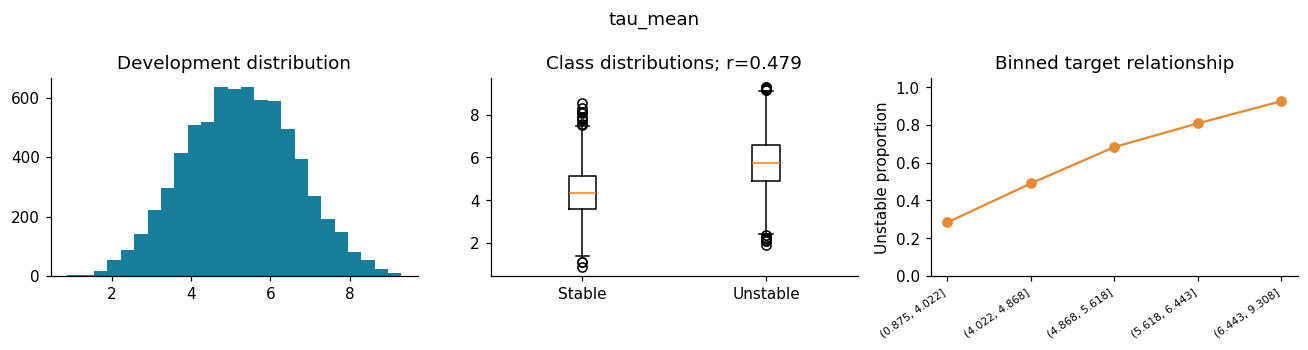

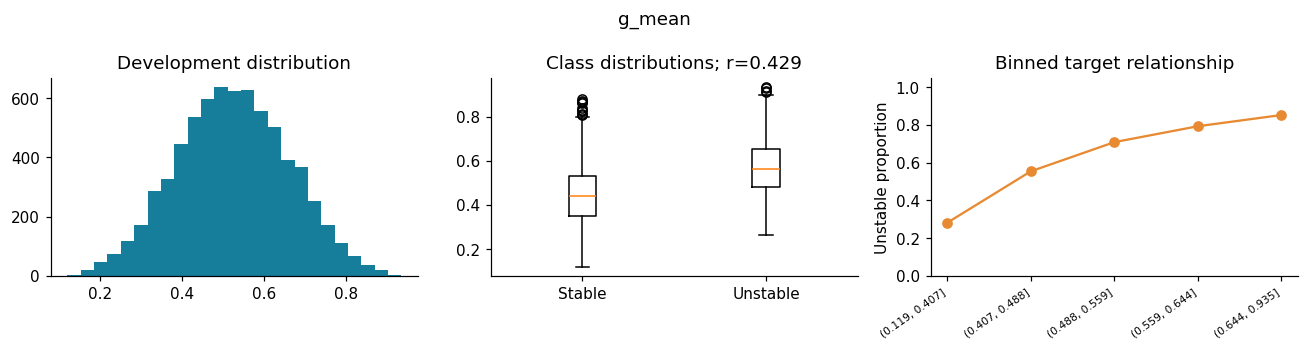

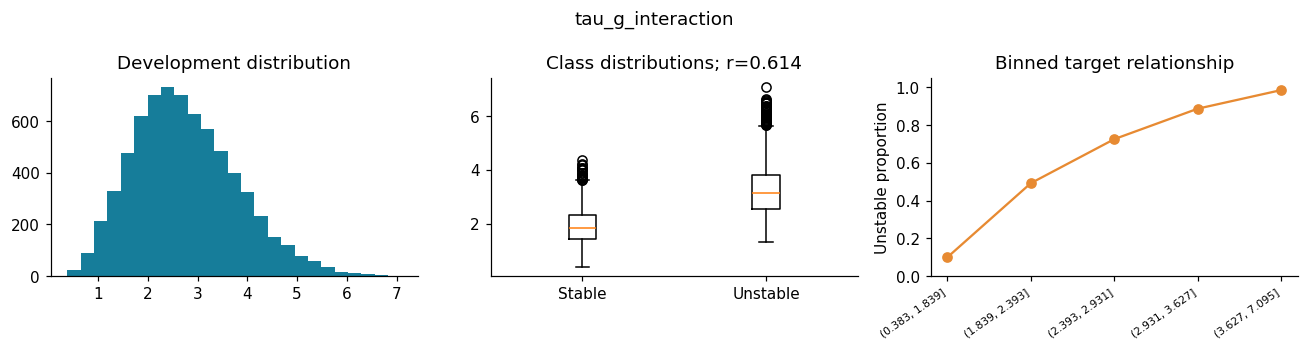

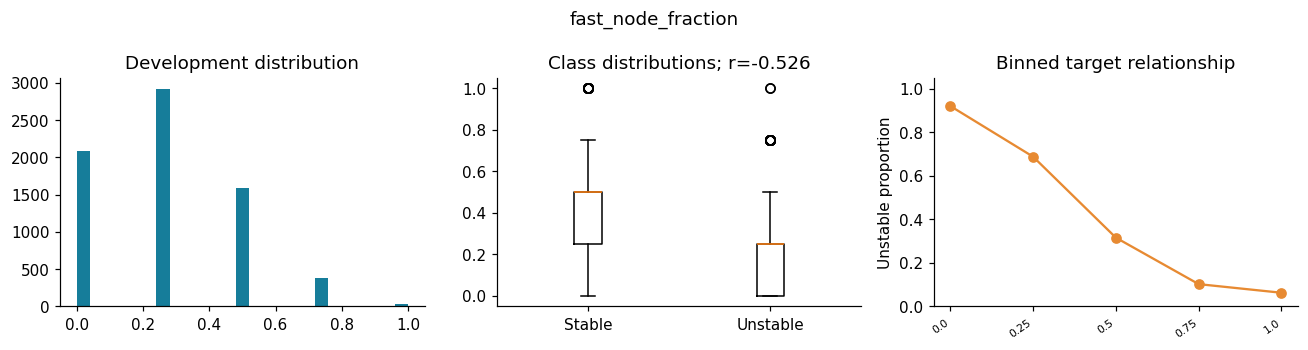

,Feature,Point-biserial r,Stable mean,Unstable mean
0,tau_mean,0.4793,4.3676,5.7425
1,g_mean,0.4293,0.4468,0.5687
2,tau_g_interaction,0.6145,1.9058,3.2366
3,fast_node_fraction,-0.5262,0.4172,0.1754


,Feature A,Feature B,Correlation
0,tau_mean,tau_g_interaction,0.7087
1,tau_mean,fast_node_fraction,-0.7664
2,g_mean,tau_g_interaction,0.6966


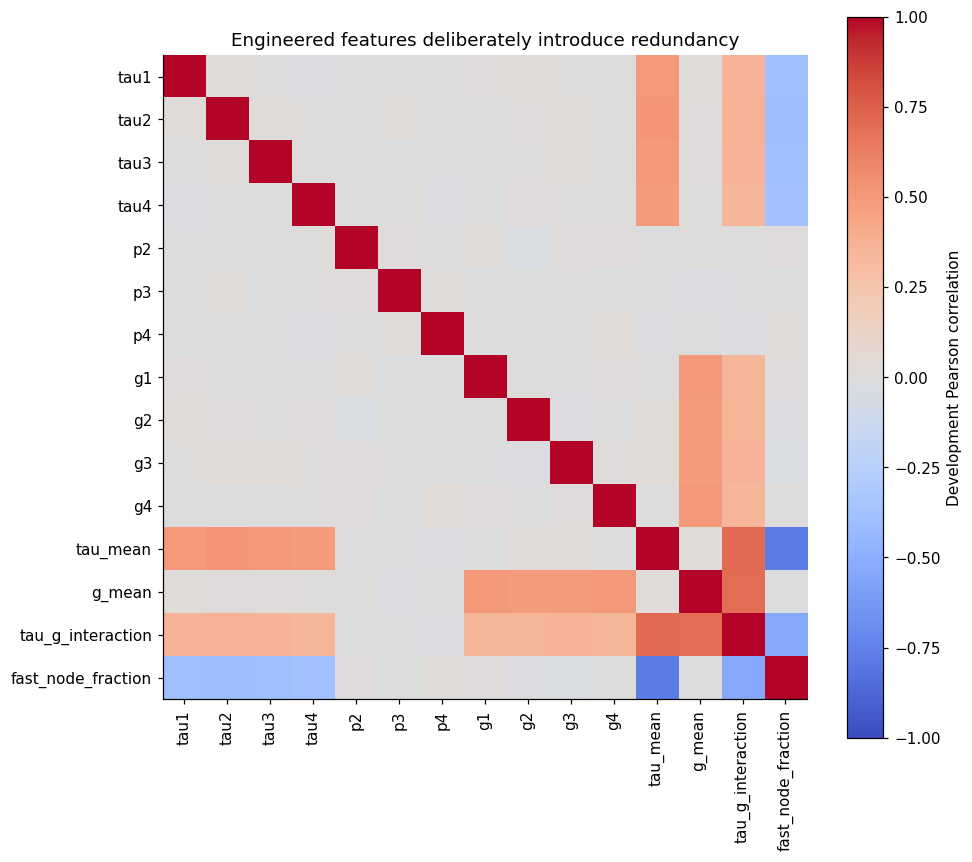

All four feature hypotheses expose aggregated or threshold structure. Their signs and binned patterns should be interpreted together: linear correlation alone misses saturation. The means share information with their component inputs, and the product shares information with both means. A large importance for one of these variables does not establish causation or make correlated alternatives unimportant.

In [5]:
feature_rows = []
for number, feature in enumerate(ENGINEERED, start=1):
    values = raw_dev[feature]
    r = pointbiserialr(y_dev, values).statistic
    feature_rows.append({'Feature':feature,'Point-biserial r':r,
                         'Stable mean':values[y_dev==0].mean(),
                         'Unstable mean':values[y_dev==1].mean()})
    bins = (pd.qcut(values,5,duplicates='drop') if feature!='fast_node_fraction' else values)
    rates = pd.DataFrame({'bin':bins,'unstable':y_dev}).groupby('bin',observed=True).agg(
        count=('unstable','size'), unstable_rate=('unstable','mean')).reset_index()
    rates.to_csv(ROOT / 'tables' / (feature+'_rates.csv'),index=False)
    fig, axes = plt.subplots(1,3,figsize=(12,3.2))
    axes[0].hist(values,bins=25,color='#167d9a'); axes[0].set_title('Development distribution')
    axes[1].boxplot([values[y_dev==0],values[y_dev==1]],tick_labels=['Stable','Unstable'])
    axes[1].set_title(f'Class distributions; r={r:.3f}')
    axes[2].plot(np.arange(len(rates)),rates.unstable_rate,'o-',color='#e78a32')
    axes[2].set_xticks(np.arange(len(rates)), [str(b) for b in rates['bin']],rotation=35,ha='right',fontsize=7)
    axes[2].set(ylim=(0,1.05),ylabel='Unstable proportion',title='Binned target relationship')
    fig.suptitle(feature)
    savefig(f'04_engineered_{number}_{feature}')
table(pd.DataFrame(feature_rows), 'engineered_associations')
correlation = raw_dev.corr()
correlation.to_csv(ROOT / 'tables/engineered_correlation_matrix.csv')
pairs = [(a,b,correlation.loc[a,b]) for i,a in enumerate(POOL) for b in POOL[i+1:]
         if abs(correlation.loc[a,b]) >= .60]
table(pd.DataFrame(pairs,columns=['Feature A','Feature B','Correlation']), 'engineered_redundancy')
fig, ax = plt.subplots(figsize=(9,8))
im=ax.imshow(correlation,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(15),POOL,rotation=90); ax.set_yticks(range(15),POOL)
fig.colorbar(im,ax=ax,label='Development Pearson correlation')
ax.set_title('Engineered features deliberately introduce redundancy')
savefig('05_engineered_correlations')
explain('All four feature hypotheses expose aggregated or threshold structure. Their signs and '
        'binned patterns should be interpreted together: linear correlation alone misses saturation. '
        'The means share information with their component inputs, and the product shares information '
        'with both means. A large importance for one of these variables does not establish causation '
        'or make correlated alternatives unimportant.')

## Task 4: Five Decision Tree configurations

Use the same `DecisionTreeClassifier(random_state=42)` defaults in all five configurations:
Gini criterion, unrestricted depth, minimum split 2, minimum leaf 1, no pruning. Studio 3 defaults
were unavailable. This is a controlled representation comparison, not tree hyperparameter tuning.

| ID | Representation | Purpose |
|---|---|---|
| DT1 | 11 original inputs | Baseline |
| DT2 | Five original inputs ranked by absolute point-biserial correlation inside each fit | Compact marginal subset |
| DT3 | 11 originals and four engineered inputs | Collective engineering test |
| DT4 | Five PCA components from MinMax-scaled originals | Unsupervised compression test |
| DT5 | tau1-tau4 and g1-g4 | Domain subset without consumer powers |

The majority reference is not a sixth tree. Training accuracy diagnoses overfitting, not generalisation.
Permutation importance is computed on the first outer validation fold for the chosen tree, so no
holdout feedback changes feature design. It remains descriptive after model selection.

In [6]:
class CorrelationSelector(BaseEstimator, TransformerMixin):
    def __init__(self, k=5): self.k = k
    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.scores_ = np.asarray([abs(pointbiserialr(y, X[c]).statistic) for c in X.columns])
        self.indices_ = np.argsort(-self.scores_,kind='stable')[:self.k]
        return self
    def transform(self, X): return X.iloc[:,self.indices_]
    def get_feature_names_out(self,input_features=None):
        return self.feature_names_in_[self.indices_]

class DomainSelector(BaseEstimator, TransformerMixin):
    def fit(self,X,y=None): return self
    def transform(self,X): return X.loc[:,DOMAIN]
    def get_feature_names_out(self,input_features=None): return np.asarray(DOMAIN,dtype=object)

def tree(): return DecisionTreeClassifier(random_state=SEED)
trees = {
    'DT1': Pipeline([('model',tree())]),
    'DT2': Pipeline([('select',CorrelationSelector(5)),('model',tree())]),
    'DT3': Pipeline([('engineer',FeatureBuilder()),('model',tree())]),
    'DT4': Pipeline([('scale',MinMaxScaler()),('pca',PCA(n_components=5,svd_solver='full')),
                     ('model',tree())]),
    'DT5': Pipeline([('domain',DomainSelector()),('model',tree())])
}
models, cv_records, dev_rows, selection_records = {}, [], [], []
feature_counts = {'DT1':11,'DT2':5,'DT3':15,'DT4':5,'DT5':8}
for model_id, estimator in trees.items():
    fold_acc=[]; start=time.perf_counter()
    for fold,(a,b) in enumerate(OUTER_FOLDS,1):
        fitted=clone(estimator).fit(X_dev.iloc[a],y_dev.iloc[a])
        score=metrics(y_dev.iloc[b],fitted.predict(X_dev.iloc[b]))
        cv_records.append({'Model':model_id,'Fold':fold,**score})
        fold_acc.append(score['accuracy'])
        if model_id=='DT2':
            selection_records.append({'Fold':str(fold), 'Selected':', '.join(fitted['select'].get_feature_names_out())})
    cv_seconds=time.perf_counter()-start
    start=time.perf_counter(); models[model_id]=clone(estimator).fit(X_dev,y_dev)
    fit_seconds=time.perf_counter()-start
    dev_rows.append({'Model':model_id,'Features':feature_counts[model_id],
        'Train accuracy':accuracy_score(y_dev,models[model_id].predict(X_dev)),
        'CV accuracy':np.mean(fold_acc),'CV SD':np.std(fold_acc,ddof=1),
        'Final fit s':fit_seconds,'CV total s':cv_seconds})
    print(model_id, 'complete; CV accuracy', round(np.mean(fold_acc),4),flush=True)
tree_dev=pd.DataFrame(dev_rows)
top_mean=tree_dev['CV accuracy'].max()
best_tree=tree_dev[tree_dev['CV accuracy'] >= top_mean-.002].sort_values(
    ['Features','CV accuracy'],ascending=[True,False]).iloc[0].Model
selection_records.append({'Fold':'Full development',
                          'Selected':', '.join(models['DT2']['select'].get_feature_names_out())})
table(pd.DataFrame(selection_records),'dt2_selected_features_by_fold')
table(tree_dev,'dt_development_results')
print('Best tree selected using development CV:',best_tree)
dt_pca=models['DT4']['pca']
print('DT4 five-component variance retained:',dt_pca.explained_variance_ratio_.sum())
table(pd.DataFrame(dt_pca.components_,columns=ORIGINAL).assign(Component=range(1,6)), 'dt4_pca_loadings')

DT1 complete; CV accuracy 0.8307


DT2 complete; CV accuracy 0.7311


DT3 complete; CV accuracy 0.8344


DT4 complete; CV accuracy 0.6773


DT5 complete; CV accuracy 0.8403


,Fold,Selected
0,1,"tau2, tau3, g3, tau1, tau4"
1,2,"tau2, tau3, tau1, g3, tau4"
2,3,"tau2, tau3, tau1, g3, tau4"
3,4,"tau2, tau3, g3, tau1, tau4"
4,5,"tau2, g3, tau1, tau4, tau3"
5,Full development,"tau2, tau3, g3, tau1, tau4"


,Model,Features,Train accuracy,CV accuracy,CV SD,Final fit s,CV total s
0,DT1,11,1.0,0.8307,0.0134,0.0614,0.4554
1,DT2,5,1.0,0.7311,0.0126,0.0527,0.3051
2,DT3,15,1.0,0.8344,0.0131,0.0936,0.4377
3,DT4,5,1.0,0.6773,0.0399,0.0494,0.3388
4,DT5,8,1.0,0.8403,0.0109,0.0435,0.2305


Best tree selected using development CV: DT5
DT4 five-component variance retained: 0.47272193414364144


,tau1,tau2,tau3,tau4,p2,p3,p4,g1,g2,g3,g4,Component
0,0.3876,0.2576,0.2703,0.0739,-0.3364,-0.2415,-0.4270,-0.0044,0.5105,0.0225,-0.2999,1
1,-0.1820,0.4606,0.4518,0.1789,0.0877,0.2303,-0.0112,-0.3829,-0.2309,0.5077,-0.0054,2
2,-0.2304,0.0194,-0.1603,0.1454,-0.3720,0.4709,0.2584,-0.4215,0.2461,-0.3621,-0.3218,3
3,0.5022,0.4421,-0.1146,-0.4298,-0.1302,0.2115,0.4924,0.1211,0.0396,0.0810,0.1659,4
4,0.0279,0.2993,-0.2381,0.1327,0.4578,0.4731,-0.2912,0.4262,0.0117,-0.0736,-0.3605,5


,Feature,Impurity importance
2,tau3,0.1379
1,tau2,0.1316
3,tau4,0.1313
4,g1,0.1263
0,tau1,0.1233
7,g4,0.1224
6,g3,0.1203
5,g2,0.1068


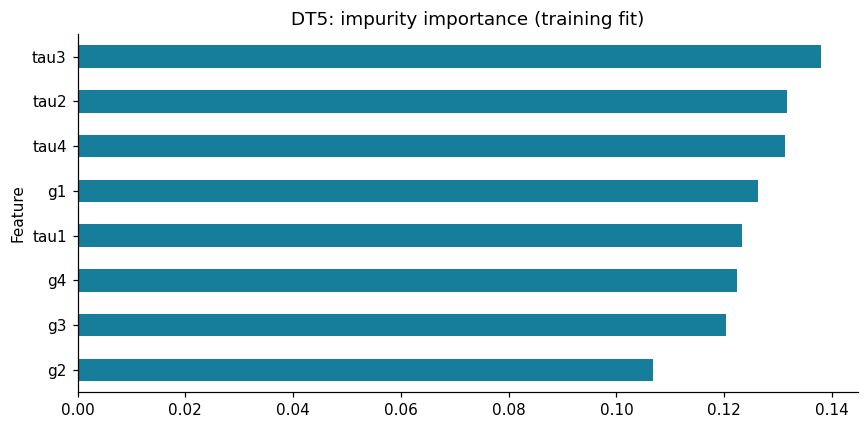

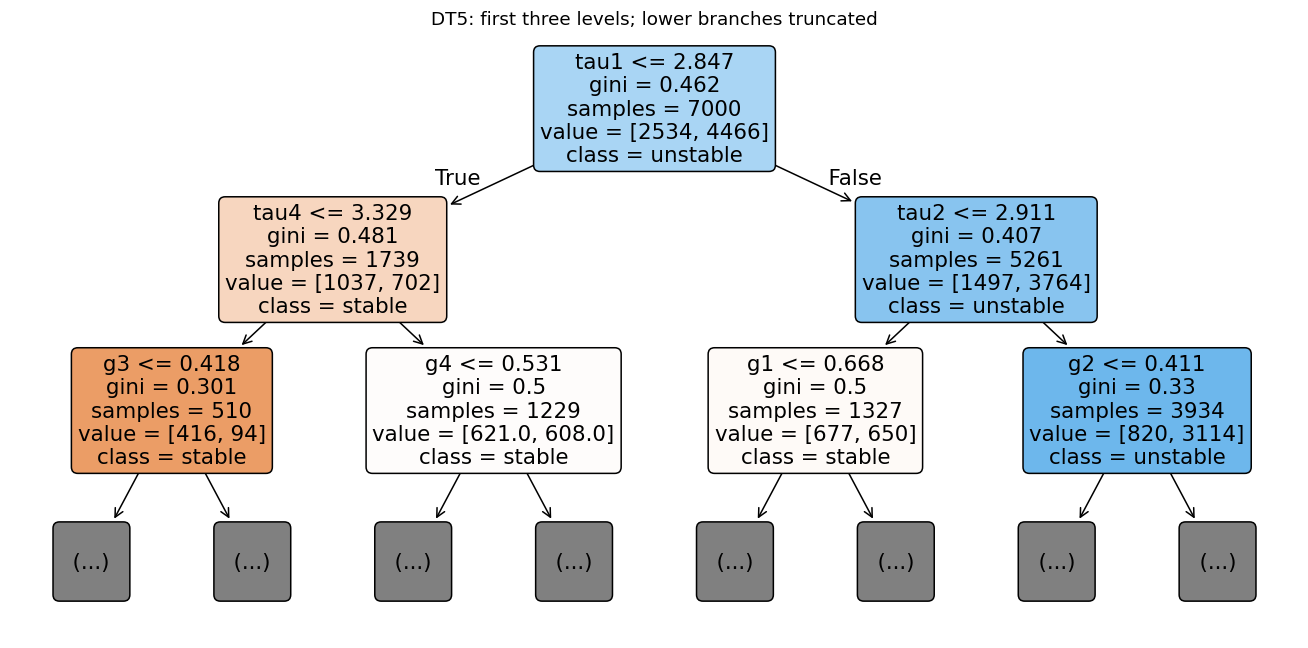

,Raw input,Accuracy decrease,Repeat SD
1,tau2,0.0667,0.0034
0,tau1,0.0604,0.0063
3,tau4,0.0597,0.0046
2,tau3,0.0593,0.0055
9,g3,0.0563,0.0057
10,g4,0.0530,0.0021
8,g2,0.0474,0.0029
7,g1,0.0460,0.0065
6,p4,0.0000,0.0000
4,p2,0.0000,0.0000


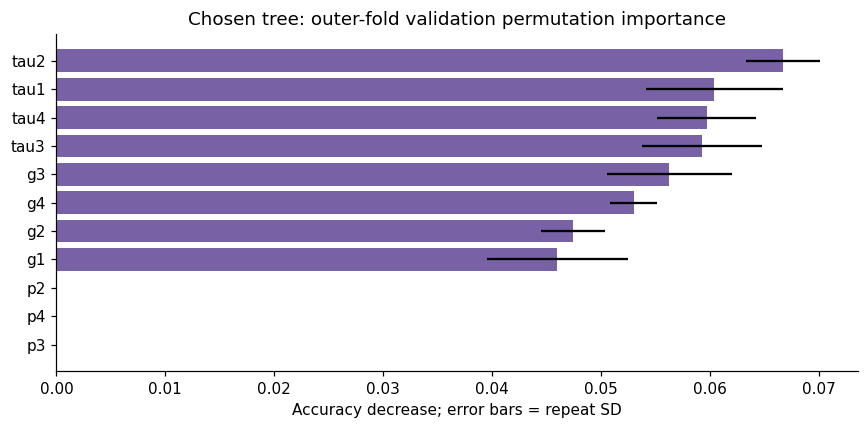

DT5 was selected from development CV. Its most important fitted split feature is tau3. Impurity importance favours variables offering useful training splits and can split credit among redundant inputs. Permuting a raw input through the pipeline also recomputes any derived features that use it; this measures input-level sensitivity, not the isolated contribution of one engineered feature. The tree diagram shows only its top levels.

In [7]:
chosen_tree=models[best_tree]
tree_names=(chosen_tree[:-1].get_feature_names_out(ORIGINAL) if len(chosen_tree.steps)>1 else np.asarray(ORIGINAL))
if best_tree=='DT4': tree_names=np.asarray(['PC'+str(i) for i in range(1,6)])
imp=pd.DataFrame({'Feature':tree_names,'Impurity importance':chosen_tree['model'].feature_importances_})
table(imp.sort_values('Impurity importance',ascending=False),'best_tree_impurity_importance')
fig,ax=plt.subplots(figsize=(8,4))
imp.sort_values('Impurity importance').plot.barh(x='Feature',y='Impurity importance',ax=ax,legend=False,color='#167d9a')
ax.set_title(best_tree+': impurity importance (training fit)')
savefig('06_best_tree_importance')
fig,ax=plt.subplots(figsize=(12,6))
plot_tree(chosen_tree['model'],feature_names=tree_names,class_names=['stable','unstable'],
          max_depth=2,filled=True,rounded=True,fontsize=14,ax=ax)
ax.set_title(best_tree+': first three levels; lower branches truncated')
savefig('07_truncated_best_tree')
a,b=OUTER_FOLDS[0]
validation_tree=clone(trees[best_tree]).fit(X_dev.iloc[a],y_dev.iloc[a])
permutation=permutation_importance(validation_tree,X_dev.iloc[b],y_dev.iloc[b],
                                 n_repeats=5,random_state=SEED,scoring='accuracy',n_jobs=1)
perm_table=pd.DataFrame({'Raw input':ORIGINAL,'Accuracy decrease':permutation.importances_mean,
                         'Repeat SD':permutation.importances_std})
table(perm_table.sort_values('Accuracy decrease',ascending=False),'best_tree_validation_permutation')
fig,ax=plt.subplots(figsize=(8,4))
perm_table=perm_table.sort_values('Accuracy decrease')
ax.barh(perm_table['Raw input'],perm_table['Accuracy decrease'],xerr=perm_table['Repeat SD'],color='#7861a5')
ax.set_title('Chosen tree: outer-fold validation permutation importance')
ax.set_xlabel('Accuracy decrease; error bars = repeat SD')
savefig('08_validation_permutation')
explain(f'{best_tree} was selected from development CV. Its most important fitted split feature is '
        f'{imp.sort_values("Impurity importance",ascending=False).iloc[0].Feature}. '
        'Impurity importance favours variables offering useful training splits and can split credit '
        'among redundant inputs. Permuting a raw input through the pipeline also recomputes any '
        'derived features that use it; this measures input-level sensitivity, not the isolated '
        'contribution of one engineered feature. The tree diagram shows only its top levels.')

## Tasks 6-9: SVM specification before final comparison

The fixed 15-feature pool is used for all four variants, independent of which tree wins.
SVM1 uses default RBF SVC (C=1, gamma='scale'). SVM2 searches the same pool, SVM3 jointly searches
SelectKBest K and SVC settings, and SVM4 jointly searches PCA retained variance and SVC settings.

The initial grid uses linear C in [0.1,1,10,100], and RBF with the same C values and gamma in
['scale',0.01,0.1,1]. Separate dictionaries avoid searching meaningless gamma values for linear SVC.
Larger C penalises errors more strongly; gamma controls RBF locality. K in [3,5,8,11,'all']
tests compression and the unreduced option. ANOVA f_classif ranks marginal class separation and
can miss joint interactions. PCA variance thresholds [0.90,0.95,0.99] use the full solver.
PCA is unsupervised: retained input variance does not guarantee retained class information.

**Bounded boundary policy.** If an initial inner winner has C=100, test C=1000 for that winning
kernel, retaining all gamma choices for RBF. If the initial RBF winner has gamma=0.01 or 1,
test respectively 0.001 or 10 with all original C values. The union is evaluated inside that same
inner training search. Selection/PCA variants use all their original representation choices in
the extension. One extension per search is allowed; unresolved boundaries are disclosed. This
rule is fixed before holdout evaluation and used consistently inside every outer fold and the
full-development search. Initial and extension records are both saved.

A timing pilot (7,000 rows; MinMax proxy for the full pool) measured about 3.39 seconds for
linear C=100 and 0.46 seconds for RBF C=10, gamma=1. It only estimated runtime and did not select
features or parameters. Grid counts and actual full search time appear below.

In [8]:
def svm_pipeline(reduction=None):
    steps=[('engineer',FeatureBuilder()),('scale',mixed_scaler())]
    if reduction=='kbest': steps.append(('select',SelectKBest(f_classif,k='all')))
    if reduction=='pca': steps.append(('pca',PCA(n_components=.95,svd_solver='full')))
    return Pipeline(steps+[('svc',SVC(cache_size=256))])

C_VALUES=[.1,1,10,100]
GAMMA_VALUES=['scale',.01,.1,1]
BASE_GRID=[{'svc__kernel':['linear'],'svc__C':C_VALUES},
           {'svc__kernel':['rbf'],'svc__C':C_VALUES,'svc__gamma':GAMMA_VALUES}]
REDUCTIONS={'SVM2':None,'SVM3':'kbest','SVM4':'pca'}
EXTRA={'SVM2':{},'SVM3':{'select__k':[3,5,8,11,'all']},
       'SVM4':{'pca__n_components':[.90,.95,.99]}}
grids={key:[dict(part,**EXTRA[key]) for part in BASE_GRID] for key in REDUCTIONS}
table(pd.DataFrame([{'Model':key,'Initial candidates':len(ParameterGrid(grid)),
                     'Inner folds':5,'Outer folds':5,'Full-development searches':1}
                    for key,grid in grids.items()]),'search_budget')
for key,grid in grids.items(): print(key,json.dumps(grid))

def search_model(model_id, X_train, y_train, label):
    estimator=svm_pipeline(REDUCTIONS[model_id])
    search=GridSearchCV(estimator,grids[model_id],cv=inner,scoring='accuracy',
                        n_jobs=N_JOBS,pre_dispatch=N_JOBS,refit=True,error_score='raise')
    search.fit(X_train,y_train)
    records=pd.DataFrame(search.cv_results_)
    records['stage']='initial'
    best_initial=search.best_params_.copy()
    extension=[]
    if best_initial['svc__C']==100:
        part={'svc__kernel':[best_initial['svc__kernel']],'svc__C':[1000]}
        if best_initial['svc__kernel']=='rbf': part['svc__gamma']=GAMMA_VALUES
        extension.append(dict(part,**EXTRA[model_id]))
    if best_initial['svc__kernel']=='rbf' and best_initial['svc__gamma'] in [.01,1]:
        boundary_gamma=.001 if best_initial['svc__gamma']==.01 else 10
        extension.append(dict({'svc__kernel':['rbf'],'svc__C':C_VALUES,
                               'svc__gamma':[boundary_gamma]},**EXTRA[model_id]))
    if extension:
        extended=GridSearchCV(estimator,extension,cv=inner,scoring='accuracy',
                              n_jobs=N_JOBS,pre_dispatch=N_JOBS,refit=True,error_score='raise')
        extended.fit(X_train,y_train)
        extra_records=pd.DataFrame(extended.cv_results_); extra_records['stage']='extension'
        records=pd.concat([records,extra_records],ignore_index=True)
        if extended.best_score_ > search.best_score_: search=extended
    records.to_csv(ROOT / 'results' / f'{model_id}_{label}_search.csv',index=False)
    return search, records

def describe_svm(estimator):
    scaled_names=estimator['scale'].get_feature_names_out()
    if 'select' in estimator.named_steps:
        names=scaled_names[estimator['select'].get_support()]
        return len(names), ', '.join(names)
    if 'pca' in estimator.named_steps:
        return int(estimator['pca'].n_components_), 'PCA components'
    return len(scaled_names), ', '.join(scaled_names)

svm_rows=[]; svm_fold_settings=[]; search_details={}; search_result_tables={}
for model_id in ['SVM1','SVM2','SVM3','SVM4']:
    print('Starting',model_id,flush=True)
    fold_acc=[]; total_start=time.perf_counter()
    for fold,(a,b) in enumerate(OUTER_FOLDS,1):
        start=time.perf_counter()
        if model_id=='SVM1':
            fitted=svm_pipeline().fit(X_dev.iloc[a],y_dev.iloc[a]); inner_best=np.nan
        else:
            search, records=search_model(model_id,X_dev.iloc[a],y_dev.iloc[a],f'outer_{fold}')
            fitted=search.best_estimator_; inner_best=float(search.best_score_)
        score=metrics(y_dev.iloc[b],fitted.predict(X_dev.iloc[b]))
        cv_records.append({'Model':model_id,'Fold':fold,**score})
        fold_acc.append(score['accuracy'])
        count, selected=describe_svm(fitted)
        settings=(search.best_params_ if model_id!='SVM1' else {'svc__C':1,'svc__kernel':'rbf','svc__gamma':'scale'})
        svm_fold_settings.append({'Model':model_id,'Fold':fold,'Features/components':count,
            'Selected':selected,'Settings':json.dumps(settings),'Inner selection accuracy':inner_best,
            'Outer accuracy':score['accuracy'],'Search and fit s':time.perf_counter()-start})
        print(model_id,'outer fold',fold,'accuracy',round(score['accuracy'],4),flush=True)
    cv_seconds=time.perf_counter()-total_start
    start=time.perf_counter()
    if model_id=='SVM1':
        fitted=svm_pipeline().fit(X_dev,y_dev)
        settings={'svc__C':1,'svc__kernel':'rbf','svc__gamma':'scale'}
        inner_best=np.nan
    else:
        search,records=search_model(model_id,X_dev,y_dev,'full_development')
        fitted=search.best_estimator_; settings=search.best_params_; inner_best=float(search.best_score_)
        search_result_tables[model_id]=records
    final_seconds=time.perf_counter()-start
    models[model_id]=fitted
    count,selected=describe_svm(fitted)
    svm_rows.append({'Model':model_id,'Features':count,'Train accuracy':accuracy_score(y_dev,fitted.predict(X_dev)),
        'CV accuracy':np.mean(fold_acc),'CV SD':np.std(fold_acc,ddof=1),
        'Support vectors':int(fitted['svc'].n_support_.sum()),
        'Final search/fit s':final_seconds,'Outer total s':cv_seconds})
    search_details[model_id]={'settings':settings,'inner_selection_accuracy':inner_best,
                              'selected':selected,'features_or_components':count}
    print('Completed',model_id,'full development; settings',settings,flush=True)
svm_dev=pd.DataFrame(svm_rows)
top_mean=svm_dev['CV accuracy'].max()
recommended=svm_dev[svm_dev['CV accuracy']>=top_mean-.002].sort_values(
    ['Features','Support vectors','CV accuracy'],ascending=[True,True,False]).iloc[0].Model
lock={'data_sha256':data_hash,'seed':SEED,'best_tree':best_tree,'recommended_svm':recommended,
      'tie_tolerance_accuracy':.002,'svm_details':search_details,
      'tree_parameters':trees['DT1']['model'].get_params()}
(ROOT / 'results/configuration_lock_before_holdout.json').write_text(json.dumps(lock,indent=2))
table(svm_dev,'svm_development_results')
print('Recommendation locked before holdout:',recommended)
table(pd.DataFrame(svm_fold_settings)[['Model','Fold','Features/components','Inner selection accuracy','Outer accuracy']],
      'svm_nested_fold_summary')
pd.DataFrame(svm_fold_settings).to_csv(ROOT / 'results/svm_fold_details.csv',index=False)
cv_frame=pd.DataFrame(cv_records)
cv_frame.to_csv(ROOT / 'results/all_outer_fold_metrics.csv',index=False)
cv_support=cv_frame.groupby('Model')[['balanced_accuracy','macro_f1','stable_recall','unstable_recall']].mean().reset_index()
table(cv_support,'cv_supporting_metrics')

,Model,Initial candidates,Inner folds,Outer folds,Full-development searches
0,SVM2,20,5,5,1
1,SVM3,100,5,5,1
2,SVM4,60,5,5,1


SVM2 [{"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10, 100]}, {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]}]
SVM3 [{"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10, 100], "select__k": [3, 5, 8, 11, "all"]}, {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1], "select__k": [3, 5, 8, 11, "all"]}]
SVM4 [{"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10, 100], "pca__n_components": [0.9, 0.95, 0.99]}, {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1], "pca__n_components": [0.9, 0.95, 0.99]}]
Starting SVM1


SVM1 outer fold 1 accuracy 0.8964


SVM1 outer fold 2 accuracy 0.9093


SVM1 outer fold 3 accuracy 0.9057


...

Completed SVM4 full development; settings {'pca__n_components': 0.99, 'svc__C': 1000, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}


,Model,Features,Train accuracy,CV accuracy,CV SD,Support vectors,Final search/fit s,Outer total s
0,SVM1,15,0.9269,0.9084,0.0095,2251,0.4933,3.1285
1,SVM2,15,0.9896,0.9541,0.0046,893,42.5841,151.0866
2,SVM3,11,0.9984,0.9553,0.0068,636,270.3766,834.4618
3,SVM4,11,0.9854,0.9559,0.0048,869,136.8206,496.8993


Recommendation locked before holdout: SVM3


,Model,Fold,Features/components,Inner selection accuracy,Outer accuracy
0,SVM1,1,15,NaN,0.8964
1,SVM1,2,15,NaN,0.9093
2,SVM1,3,15,NaN,0.9057
3,SVM1,4,15,NaN,0.9229
4,SVM1,5,15,NaN,0.9079
5,SVM2,1,15,0.9486,0.9536
6,SVM2,2,15,0.9521,0.9514
7,SVM2,3,15,0.9521,0.9507
8,SVM2,4,15,0.9450,0.9621
9,SVM2,5,15,0.9511,0.9529


,Model,balanced_accuracy,macro_f1,stable_recall,unstable_recall
0,DT1,0.8155,0.8163,0.7605,0.8706
1,DT2,0.7107,0.7100,0.6366,0.7848
2,DT3,0.8194,0.8203,0.7648,0.8739
3,DT4,0.6533,0.6526,0.5663,0.7403
4,DT5,0.8257,0.8266,0.7727,0.8786
5,SVM1,0.8960,0.8999,0.8508,0.9411
6,SVM2,0.9494,0.9503,0.9321,0.9666
7,SVM3,0.9515,0.9516,0.9376,0.9653
8,SVM4,0.9516,0.9522,0.9361,0.9671


## Tasks 7-9: Tuning, feature selection and PCA diagnostics

The following diagnostics use full-development inner selection results, distinctly labelled from
outer evaluation. K curves show the best inner score per K after optimising SVC settings; they are
not independent generalisation estimates. Exact selected features and PCA loadings are retained.

,Model,Kernel,C,Gamma,K / variance,Inner accuracy
0,SVM1,rbf,1,scale,all,NaN
1,SVM2,rbf,1000,0.1,all,0.9517
2,SVM3,rbf,1000,scale,11,0.9594
3,SVM4,rbf,1000,0.1,0.99,0.9537


SVM2 top full-development inner candidates:


,params,mean_test_score,std_test_score
0,"{'svc__C': 1000, 'svc__gamma': 0.1, 'svc__kern...",0.9517,0.0086
1,"{'svc__C': 100, 'svc__gamma': 'scale', 'svc__k...",0.9509,0.0093
2,"{'svc__C': 100, 'svc__gamma': 0.1, 'svc__kerne...",0.9461,0.0060
3,"{'svc__C': 1000, 'svc__gamma': 'scale', 'svc__...",0.9457,0.0064
4,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.9413,0.0085


SVM3 top full-development inner candidates:


,params,mean_test_score,std_test_score
0,"{'select__k': 11, 'svc__C': 1000, 'svc__gamma'...",0.9594,0.0076
1,"{'select__k': 11, 'svc__C': 1000, 'svc__gamma'...",0.9549,0.0060
2,"{'select__k': 11, 'svc__C': 100, 'svc__gamma':...",0.9536,0.0074
3,"{'select__k': 11, 'svc__C': 1000, 'svc__gamma'...",0.9520,0.0087
4,"{'select__k': 'all', 'svc__C': 1000, 'svc__gam...",0.9517,0.0086


SVM4 top full-development inner candidates:


,params,mean_test_score,std_test_score
0,"{'pca__n_components': 0.99, 'svc__C': 1000, 's...",0.9537,0.0082
1,"{'pca__n_components': 0.99, 'svc__C': 100, 'sv...",0.9464,0.0099
2,"{'pca__n_components': 0.99, 'svc__C': 100, 'sv...",0.9457,0.0083
3,"{'pca__n_components': 0.99, 'svc__C': 1000, 's...",0.9450,0.0085
4,"{'pca__n_components': 0.99, 'svc__C': 10, 'svc...",0.9423,0.0081


,Feature,ANOVA F,Selected
11,tau_g_interaction,4245.1819,True
14,fast_node_fraction,2679.1966,True
12,tau_mean,2087.0516,True
13,g_mean,1580.8529,True
1,tau2,493.6893,True
2,tau3,434.1608,True
9,g3,413.3286,True
0,tau1,408.5001,True
3,tau4,394.2561,True
8,g2,345.8181,True


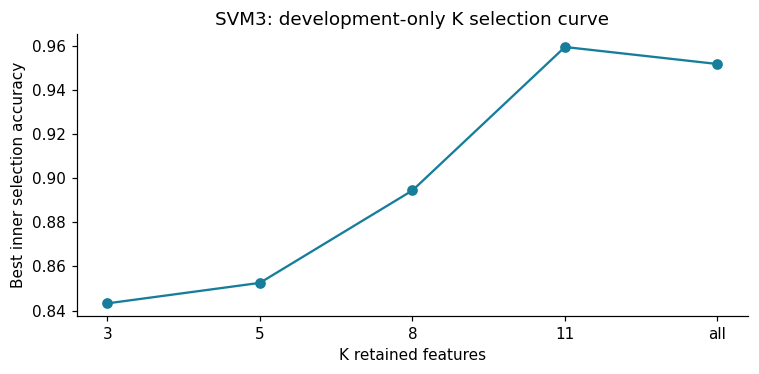

,Components,Cumulative variance
0,1,0.3836
1,2,0.7427
2,3,0.7723
3,4,0.8010
4,5,0.8296
5,6,0.8579
6,7,0.8860
7,8,0.9132
8,9,0.9401
9,10,0.9667


,Component,Top absolute loadings
0,PC1,"tau_mean (+0.794), g_mean (+0.507), tau_g_inte..."
1,PC2,"g_mean (+0.811), tau_mean (-0.508), g1 (+0.122)"
2,PC3,"g2 (+0.543), p2 (-0.377), p4 (-0.357)"
3,PC4,"p4 (+0.561), p3 (+0.536), g2 (+0.328)"
4,PC5,"tau1 (+0.583), g1 (+0.431), tau4 (-0.317)"
5,PC6,"tau4 (+0.530), p2 (+0.415), g1 (+0.378)"
6,PC7,"g4 (+0.504), tau2 (-0.433), tau4 (+0.415)"
7,PC8,"tau3 (+0.717), g1 (+0.309), tau4 (-0.283)"
8,PC9,"tau2 (+0.565), tau1 (-0.495), p3 (-0.450)"
9,PC10,"g4 (+0.441), p2 (+0.408), g3 (-0.380)"


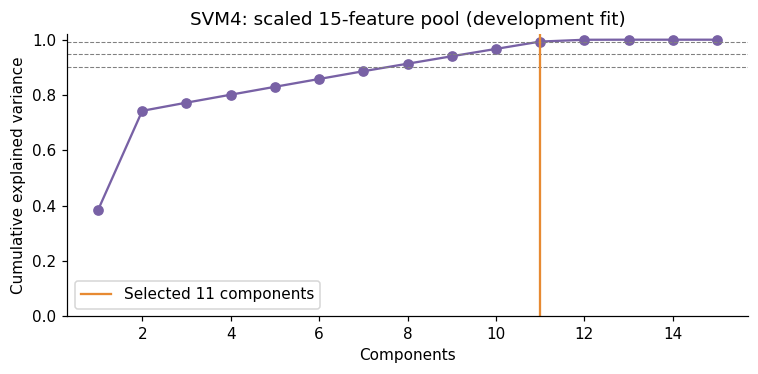

SVM3 selected 11 features: tau1, tau2, tau3, tau4, g2, g3, g4, tau_g_interaction, tau_mean, g_mean, fast_node_fraction. SVM4 retained 11 components and 99.32% of scaled development variance. Loading signs are arbitrary up to a simultaneous component sign flip. These PCA results depend on the explicitly chosen mixed scaling; variance in differently scaled coordinates is not raw physical variance. Fold-specific K, components and settings are saved separately.

After the single bounded extension, remaining search-boundary settings occur in: SVM2, SVM3, SVM4. The search is finite and does not prove globally optimal parameters.

In [9]:
parameter_rows=[]
for model_id,info in search_details.items():
    setting=info['settings']
    parameter_rows.append({'Model':model_id,'Kernel':setting['svc__kernel'], 'C':setting['svc__C'],
                           'Gamma':str(setting.get('svc__gamma','not applicable')),
                           'K / variance':str(setting.get('select__k',setting.get('pca__n_components','all'))),
                           'Inner accuracy':info['inner_selection_accuracy']})
table(pd.DataFrame(parameter_rows),'svm_best_parameters')
for model_id in ['SVM2','SVM3','SVM4']:
    records=search_result_tables[model_id]
    top=records.sort_values('mean_test_score',ascending=False).head(5)
    print(model_id,'top full-development inner candidates:')
    table(top[['params','mean_test_score','std_test_score']].reset_index(drop=True),model_id+'_top_search_results')
selected_model=models['SVM3']
selection=selected_model['select']
selected_names=selected_model['scale'].get_feature_names_out()
selection_table=pd.DataFrame({'Feature':selected_names,'ANOVA F':selection.scores_,
                             'Selected':selection.get_support()}).sort_values('ANOVA F',ascending=False)
table(selection_table,'svm3_feature_scores')
k_records=search_result_tables['SVM3'].copy()
k_records['K']=k_records['param_select__k'].astype(str)
k_curve=k_records.groupby('K')['mean_test_score'].max().reindex(['3','5','8','11','all'])
fig,ax=plt.subplots(figsize=(7,3.5))
ax.plot(k_curve.index,k_curve.values,'o-',color='#167d9a')
ax.set(xlabel='K retained features',ylabel='Best inner selection accuracy',
       title='SVM3: development-only K selection curve')
savefig('09_k_selection_curve')
selected_pca=models['SVM4']['pca']
scaled_names=models['SVM4']['scale'].get_feature_names_out()
full_pca=PCA(svd_solver='full').fit(models['SVM4']['scale'].transform(raw_dev))
cumulative=np.cumsum(full_pca.explained_variance_ratio_)
table(pd.DataFrame({'Components':range(1,len(cumulative)+1),'Cumulative variance':cumulative}), 'svm4_pca_variance')
loadings=pd.DataFrame(selected_pca.components_,columns=scaled_names)
loadings.insert(0,'Component',['PC'+str(i) for i in range(1,len(loadings)+1)])
loadings.to_csv(ROOT / 'tables/svm4_pca_loadings.csv',index=False)
loading_rows=[]
for i,component in enumerate(selected_pca.components_,1):
    strongest=np.argsort(-np.abs(component))[:3]
    loading_rows.append({'Component':'PC'+str(i),'Top absolute loadings':
                         ', '.join(f'{scaled_names[j]} ({component[j]:+.3f})' for j in strongest)})
table(pd.DataFrame(loading_rows),'svm4_pca_top_loadings')
fig,ax=plt.subplots(figsize=(7,3.5))
ax.plot(range(1,len(cumulative)+1),cumulative,'o-',color='#7861a5')
for threshold in [.90,.95,.99]: ax.axhline(threshold,color='grey',ls='--',lw=.7)
ax.axvline(selected_pca.n_components_,color='#e78a32',label=f'Selected {selected_pca.n_components_} components')
ax.set(xlabel='Components',ylabel='Cumulative explained variance',ylim=(0,1.02),
       title='SVM4: scaled 15-feature pool (development fit)'); ax.legend()
savefig('10_pca_cumulative_variance')
explain(f'SVM3 selected {search_details["SVM3"]["features_or_components"]} features: '
        f'{search_details["SVM3"]["selected"]}. '
        f'SVM4 retained {selected_pca.n_components_} components and '
        f'{selected_pca.explained_variance_ratio_.sum():.2%} of scaled development variance. '
        'Loading signs are arbitrary up to a simultaneous component sign flip. These PCA results '
        'depend on the explicitly chosen mixed scaling; variance in differently scaled coordinates '
        'is not raw physical variance. Fold-specific K, components and settings are saved separately.')
boundary_models=[key for key,info in search_details.items() if key!='SVM1' and
                 (info['settings']['svc__C'] in [.1,1000] or
                  info['settings'].get('svc__gamma') in [.001,10])]
explain('After the single bounded extension, remaining search-boundary settings occur in: '
        +(', '.join(boundary_models) if boundary_models else 'none of the final development winners')+
        '. The search is finite and does not prove globally optimal parameters.')

### Interpreting the reduction and engineered redundancy

The means introduce exact linear relationships: `4*tau_mean = tau1+tau2+tau3+tau4`
and `4*g_mean = g1+g2+g3+g4`. Consequently, the 15-feature pool has at most 13 independent
linear directions even before considering other correlations. Per-feature affine scaling
preserves these dependencies after centering; the complete PCA spectrum can therefore include
approximately zero trailing eigenvalues. The product and fast-node fraction add nonlinear
representations of existing measurements, rather than new independently measured information.

In the actual SVM3 selection, an omitted node input is reconstructable from retained raw inputs and their mean: `g1 = 4*g_mean - g2 - g3 - g4`. Thus dropping this named input does not necessarily discard its information. The selected representation changes the geometry seen by the SVM, and removes consumer powers where absent; a better score should not be interpreted as proof that the omitted node has no engineering influence.

K was selected using the prespecified inner CV search, not the final holdout. The selected component/feature count is one measure of representation size; support vectors and fit/search cost describe other aspects of complexity. Both reduction methods still require measuring the inputs used to form retained aggregates or components.

## Task 5: First Comparison Table with visuals (five trees)

All nine configurations and the recommendation have now been frozen using development evidence.
The holdout is evaluated once per fixed final model below. No parameter or representation is
revised after these results. First Comparison Table includes exactly five Decision Tree rows;
holdout supporting metrics and SD-labelled development error bars are supplied alongside it.

,Model,Features,Train accuracy,CV accuracy,CV SD,Holdout accuracy,Final fit s
0,DT1,11,1.0,0.8307,0.0134,0.8553,0.0614
1,DT2,5,1.0,0.7311,0.0126,0.7280,0.0527
2,DT3,15,1.0,0.8344,0.0131,0.8397,0.0936
3,DT4,5,1.0,0.6773,0.0399,0.6597,0.0494
4,DT5,8,1.0,0.8403,0.0109,0.8573,0.0435


,Model,balanced_accuracy,macro_f1,stable_recall,unstable_recall
0,DT1,0.8466,0.8444,0.8149,0.8783
1,DT2,0.7044,0.7049,0.6188,0.7900
2,DT3,0.8254,0.8261,0.7735,0.8772
3,DT4,0.6375,0.6357,0.5571,0.7179
4,DT5,0.8494,0.8467,0.8204,0.8783


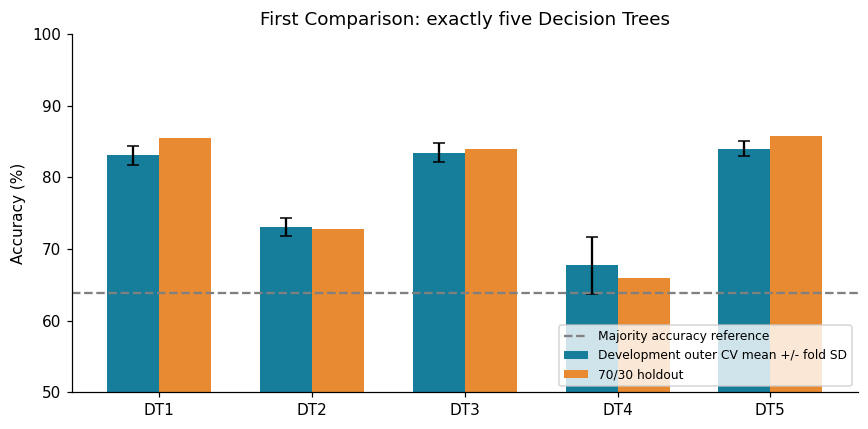

**Which representation won?** The predeclared rule selected DT5, with mean CV accuracy 84.03%. **Did engineering help?** DT3 minus DT1 is +0.37 percentage points in CV. **What happened without consumer powers?** DT5 minus DT1 is +0.96 points. **Did PCA lose predictive signal?** DT4 minus DT1 is -15.34 points while retaining 47.27% of input variance. **Tradeoffs and overfitting:** training minus CV gaps range from 15.97 to 32.27 points; unrestricted trees can memorise training configurations. Compact inputs may improve explanation but discard interactions. A single five-fold comparison does not establish statistical significance. [Studio_3_Task_5_Exact_Reflection_Prompts] remain to be reconciled.

In [10]:
holdout_rows=[]; holdout_predictions={}
for model_id,model in models.items():
    prediction=model.predict(X_test)
    holdout_predictions[model_id]=prediction
    holdout_rows.append({'Model':model_id,**metrics(y_test,prediction)})
    pd.DataFrame({'row_index':test_idx,'truth':y_test.to_numpy(),'prediction':prediction}).to_csv(
        ROOT / 'results' / (model_id+'_holdout_predictions.csv'),index=False)
holdout=pd.DataFrame(holdout_rows)
tree_summary=tree_dev.merge(holdout,on='Model')
svm_summary=svm_dev.merge(holdout,on='Model')
tree_summary.to_csv(ROOT / 'tables/First_Comparison_Table_full.csv',index=False)
svm_summary.to_csv(ROOT / 'tables/Final_Comparison_Table_full.csv',index=False)
first=tree_summary[['Model','Features','Train accuracy','CV accuracy','CV SD','accuracy','Final fit s']].rename(
    columns={'accuracy':'Holdout accuracy'})
table(first,'First_Comparison_Table')
table(tree_summary[['Model','balanced_accuracy','macro_f1','stable_recall','unstable_recall']],
      'dt_holdout_supporting_metrics')

def comparison_plot(frame,title,name):
    fig,ax=plt.subplots(figsize=(8,4))
    positions=np.arange(len(frame)); width=.34
    ax.bar(positions-width/2,100*frame['CV accuracy'],width,yerr=100*frame['CV SD'],
           label='Development outer CV mean +/- fold SD',color='#167d9a',capsize=4)
    ax.bar(positions+width/2,100*frame['accuracy'],width,label='70/30 holdout',color='#e78a32')
    ax.axhline(63.8,ls='--',color='grey',label='Majority accuracy reference')
    ax.set(xticks=positions,xticklabels=frame.Model,ylabel='Accuracy (%)',ylim=(50,100),title=title)
    ax.legend(loc='lower right',fontsize=8)
    savefig(name)
comparison_plot(tree_summary,'First Comparison: exactly five Decision Trees','11_first_comparison')
d=tree_dev.set_index('Model')['CV accuracy']
gaps=(tree_dev['Train accuracy']-tree_dev['CV accuracy'])*100
dt4_variance=dt_pca.explained_variance_ratio_.sum()
explain(f'**Which representation won?** The predeclared rule selected {best_tree}, with mean '
        f'CV accuracy {d[best_tree]:.2%}. **Did engineering help?** DT3 minus DT1 is '
        f'{100*(d["DT3"]-d["DT1"]):+.2f} percentage points in CV. '
        f'**What happened without consumer powers?** DT5 minus DT1 is '
        f'{100*(d["DT5"]-d["DT1"]):+.2f} points. **Did PCA lose predictive signal?** '
        f'DT4 minus DT1 is {100*(d["DT4"]-d["DT1"]):+.2f} points while retaining '
        f'{dt4_variance:.2%} of input variance. **Tradeoffs and overfitting:** training minus '
        f'CV gaps range from {gaps.min():.2f} to {gaps.max():.2f} points; unrestricted trees '
        'can memorise training configurations. Compact inputs may improve explanation but '
        'discard interactions. A single five-fold comparison does not establish statistical '
        'significance. [Studio_3_Task_5_Exact_Reflection_Prompts] remain to be reconciled.')

## Task 10: Final Comparison Table with visuals (four SVM variants)

Accuracy and SD in the following tables are proportions (multiply by 100 for percentages).
Supporting metrics are holdout values; CV supporting metrics were displayed earlier.
SVM1 has ordinary five-fold CV; SVM2-4 have nested outer five-fold CV. Runtime includes the
full-development search and refit where applicable, so it must not be interpreted as inference
latency or a like-for-like standalone estimator fit comparison.

,Model,Features,Train accuracy,CV accuracy,CV SD,Holdout accuracy,Support vectors
0,SVM1,15,0.9269,0.9084,0.0095,0.9220,2251
1,SVM2,15,0.9896,0.9541,0.0046,0.9660,893
2,SVM3,11,0.9984,0.9553,0.0068,0.9673,636
3,SVM4,11,0.9854,0.9559,0.0048,0.9640,869


,Model,balanced_accuracy,macro_f1,stable_recall,unstable_recall
0,SVM1,0.9102,0.9146,0.8674,0.9530
1,SVM2,0.9634,0.9632,0.9540,0.9728
2,SVM3,0.9644,0.9646,0.9540,0.9749
3,SVM4,0.9614,0.9611,0.9521,0.9707


,Model,Final search/fit s,Outer total s
0,SVM1,0.4933,3.1285
1,SVM2,42.5841,151.0866
2,SVM3,270.3766,834.4618
3,SVM4,136.8206,496.8993


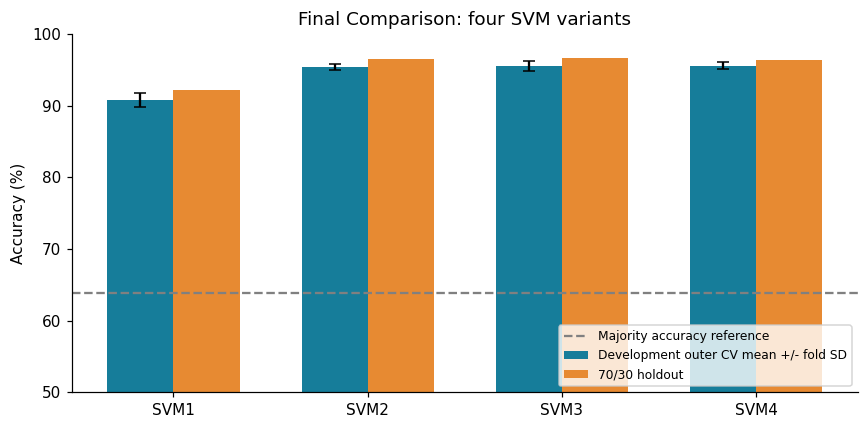

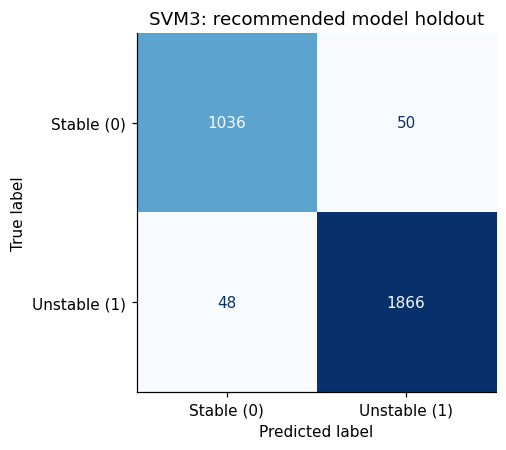

,Fold,Recommended SVM minus best DT (pp)
0,1,11.2143
1,2,11.1429
2,3,13.1429
3,4,11.0714
4,5,10.9286


**Did SVM improve on DT?** Recommended SVM3 minus DT5 is +11.50 percentage points in development CV and +11.00 points on holdout. **Did tuning help?** SVM2 minus SVM1 is +4.57 CV points and +4.40 holdout points. **Which features survived K-best?** tau1, tau2, tau3, tau4, g2, g3, g4, tau_g_interaction, tau_mean, g_mean, fast_node_fraction. K-best minus tuned unreduced SVM2 is +0.11 CV points. **Did PCA reduce complexity at acceptable cost?** SVM4 uses 11 components from 15 inputs; its CV change from SVM2 is +0.17 points. The recommendation applies the predeclared accuracy and simplicity rule; feature count alone does not measure model complexity, so support vectors and search runtime are also shown.

**Which errors are most concerning?** With rows=true class and columns=predicted class, the bottom-left entry is 48 unstable cases predicted stable. These false assurances would be the more concerning error in a screening use. The top-right entry is 50 stable cases predicted unstable. Stable recall is 95.40%; unstable recall is 97.49%. No cost weighting or decision threshold was tuned after viewing these errors. An operational deployment would require domain-specific costs and external validation. [Studio_3_Task_10_Exact_Reflection_Prompts] remain to be reconciled.

In [11]:
final=svm_summary[['Model','Features','Train accuracy','CV accuracy','CV SD','accuracy','Support vectors']].rename(
    columns={'accuracy':'Holdout accuracy'})
table(final,'Final_Comparison_Table')
table(svm_summary[['Model','balanced_accuracy','macro_f1','stable_recall','unstable_recall']],
      'svm_holdout_supporting_metrics')
table(svm_summary[['Model','Final search/fit s','Outer total s']], 'svm_runtime')
comparison_plot(svm_summary,'Final Comparison: four SVM variants','12_final_comparison')
fig,ax=plt.subplots(figsize=(5,4.2))
ConfusionMatrixDisplay.from_predictions(y_test,holdout_predictions[recommended],
    display_labels=['Stable (0)','Unstable (1)'],cmap='Blues',colorbar=False,ax=ax)
ax.set_title(recommended+': recommended model holdout')
savefig('13_recommended_confusion_matrix')
v=svm_summary.set_index('Model'); t=tree_summary.set_index('Model')
cm=confusion_matrix(y_test,holdout_predictions[recommended],labels=[0,1])
paired=cv_frame.pivot(index='Fold',columns='Model',values='accuracy')
paired_delta=(paired[recommended]-paired[best_tree])*100
table(pd.DataFrame({'Fold':paired_delta.index,'Recommended SVM minus best DT (pp)':paired_delta.values}),
      'paired_svm_tree_outer_differences')
explain(f'**Did SVM improve on DT?** Recommended {recommended} minus {best_tree} is '
        f'{100*(v.loc[recommended,"CV accuracy"]-t.loc[best_tree,"CV accuracy"]):+.2f} '
        f'percentage points in development CV and '
        f'{100*(v.loc[recommended,"accuracy"]-t.loc[best_tree,"accuracy"]):+.2f} points on holdout. '
        f'**Did tuning help?** SVM2 minus SVM1 is '
        f'{100*(v.loc["SVM2","CV accuracy"]-v.loc["SVM1","CV accuracy"]):+.2f} CV points and '
        f'{100*(v.loc["SVM2","accuracy"]-v.loc["SVM1","accuracy"]):+.2f} holdout points. '
        f'**Which features survived K-best?** {search_details["SVM3"]["selected"]}. '
        f'K-best minus tuned unreduced SVM2 is '
        f'{100*(v.loc["SVM3","CV accuracy"]-v.loc["SVM2","CV accuracy"]):+.2f} CV points. '
        f'**Did PCA reduce complexity at acceptable cost?** SVM4 uses '
        f'{v.loc["SVM4","Features"]} components from 15 inputs; its CV change from SVM2 is '
        f'{100*(v.loc["SVM4","CV accuracy"]-v.loc["SVM2","CV accuracy"]):+.2f} points. '
        'The recommendation applies the predeclared accuracy and simplicity rule; feature count '
        'alone does not measure model complexity, so support vectors and search runtime are also shown.')
explain(f'**Which errors are most concerning?** With rows=true class and columns=predicted class, '
        f'the bottom-left entry is {cm[1,0]} unstable cases predicted stable. These false assurances '
        f'would be the more concerning error in a screening use. The top-right entry is {cm[0,1]} '
        f'stable cases predicted unstable. Stable recall is {v.loc[recommended,"stable_recall"]:.2%}; '
        f'unstable recall is {v.loc[recommended,"unstable_recall"]:.2%}. '
        'No cost weighting or decision threshold was tuned after viewing these errors. '
        'An operational deployment would require domain-specific costs and external validation. '
        '[Studio_3_Task_10_Exact_Reflection_Prompts] remain to be reconciled.')

## Conclusion and limitations

The recommendation below is based on development CV with the locked simplicity rule. The
holdout provides a subsequent check, and does not choose the winner. Small numerical differences
should not be presented as convincing improvements without additional independent evidence.

Limitations include prior full-data Task 1 EDA, simulation-only configurations, one split and one
five-fold partition, correlated engineered representations, finite parameter grids, and omitted
real-grid dynamics and operating distributions. PCA preserves scaled input variance, not safety;
ANOVA selection is univariate; unrestricted trees overfit. Neither the product feature nor a
3-second reaction threshold proves a physical stability criterion. No real-grid generalisation
or deployment fitness has been established.

In [12]:
recommendation={
    'recommended_model':recommended,'best_decision_tree':best_tree,
    'svm_cv_accuracy':float(v.loc[recommended,'CV accuracy']),
    'svm_cv_sd':float(v.loc[recommended,'CV SD']),
    'svm_holdout_accuracy':float(v.loc[recommended,'accuracy']),
    'svm_holdout_balanced_accuracy':float(v.loc[recommended,'balanced_accuracy']),
    'svm_holdout_macro_f1':float(v.loc[recommended,'macro_f1']),
    'confusion_matrix_rows_true_columns_predicted':cm.tolist(),
    'settings':search_details[recommended]['settings'],
    'selected_representation':search_details[recommended]['selected'],
    'features_or_components':int(v.loc[recommended,'Features']),
    'svm_minus_best_dt_cv_pp':float(100*(v.loc[recommended,'CV accuracy']-t.loc[best_tree,'CV accuracy'])),
    'svm_minus_best_dt_holdout_pp':float(100*(v.loc[recommended,'accuracy']-t.loc[best_tree,'accuracy']))}
(ROOT / 'results/recommendation.json').write_text(json.dumps(recommendation,indent=2))
explain(f'**Recommendation:** {recommended}, with development accuracy '
        f'{recommendation["svm_cv_accuracy"]:.2%} +/- {recommendation["svm_cv_sd"]:.2%} fold SD, '
        f'holdout accuracy {recommendation["svm_holdout_accuracy"]:.2%}, balanced accuracy '
        f'{recommendation["svm_holdout_balanced_accuracy"]:.2%} and macro-F1 '
        f'{recommendation["svm_holdout_macro_f1"]:.4f}. This is the best-supported choice under '
        'the specified comparison protocol, not a validated real-grid control system.')
assert len(tree_summary)==5 and len(svm_summary)==4
assert all(set(X_dev.columns).isdisjoint({'stab','stabf','p1'}) for _ in [0])
assert all(len(model.predict(X_test.iloc[:3]))==3 for model in models.values())
assert np.isfinite(cv_frame.select_dtypes(include='number').to_numpy()).all()
print('Integrity checks passed: five trees; four SVMs; shared split; no excluded inputs; finite CV outputs.')

**Recommendation:** SVM3, with development accuracy 95.53% +/- 0.68% fold SD, holdout accuracy 96.73%, balanced accuracy 96.44% and macro-F1 0.9646. This is the best-supported choice under the specified comparison protocol, not a validated real-grid control system.

Integrity checks passed: five trees; four SVMs; shared split; no excluded inputs; finite CV outputs.


## Demonstration: reproducible small action

This cell predicts three saved holdout rows using the already-fitted recommendation. Rerunning
it does not retrain the model or launch a search. Explain the inputs, class mapping and errors
in your own words. The separate `Demo_Rehearsal.md` provides a measured-result 6-8 minute outline.

In [13]:
demo_rows=X_test.iloc[:3]
table(pd.DataFrame({'Source row':demo_rows.index,'Actual class':y_test.iloc[:3].map({0:'stable',1:'unstable'}).values,
                    'Predicted class':pd.Series(models[recommended].predict(demo_rows)).map({0:'stable',1:'unstable'}).values}),
      'demo_three_predictions')

,Source row,Actual class,Predicted class
0,8779,unstable,unstable
1,9156,unstable,unstable
2,5371,stable,stable
